### Lab 8 Meeting 2 ###

In [9]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise import ReadoutError
from qiskit_aer.noise import depolarizing_error
from qiskit.visualization import plot_bloch_multivector, plot_state_qsphere, plot_histogram
import matplotlib.pyplot as plt
import numpy as np

sim = AerSimulator()

In [4]:
# Ideal Circuit

qc = QuantumCircuit(2,2)
qc.h(0)
qc.cx(0,1)
qc.measure([0,1],[0,1])


In [10]:
# Noise
#   - Gate noise (depolarizing error on CX gates)
#   - Readout noise (Classical bit-flip during measurement)

noise_model = NoiseModel()

# Gate noise: Depolarizing gate error with 5% error rate on every two-qubit CX gate
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.05, 2), ['cx'])

# Readout error (e.g., 10-20% misread per qubit)
p0given1 = 0.15 # misread 1 as 0
p1given0 = 0.15 # misread 0 as 1

readout = ReadoutError([[1-p1given0, p1given0],[p0given1, 1-p0given1]])

for qubit in range(2):
    noise_model.add_readout_error(readout, [qubit])

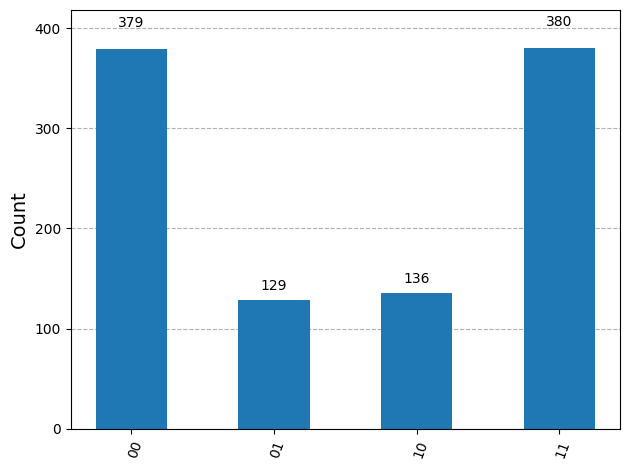

In [11]:
# 1. Initialize the simulator with the noise model
backend = AerSimulator(noise_model=noise_model)

# 2. Transpile and Run (Replaces execute)
transpiled_qc = transpile(qc, backend)
job = backend.run(transpiled_qc, shots=1024)

# 3. Get results and plot
noisy_counts = job.result().get_counts()
plot_histogram(noisy_counts)